# Análisis exploratorio de churn sintético de empleados

Este notebook genera datos ficticios con `churn_ml.data.generate_employee_data` y explora su calidad, distribuciones y relación entre variables y churn. **No lee el CSV bancario ni utiliza datos de personas reales.**

La etiqueta se simula a partir de las variables del generador; los patrones encontrados sirven para comprobar el flujo de análisis, no describen relaciones laborales reales ni permiten conclusiones sobre empleados.

## 1. Configuración y generación reproducible

Ajusta `N_SAMPLES` y `RANDOM_STATE` para cambiar el tamaño de la muestra o reproducir otra muestra sintética. El CSV sintético se guarda en `data/churn_empleados_sintetico.csv`, relativo a la raíz del repositorio. La carpeta se crea si no existe.

In [19]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "churn_ml" / "data.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró churn_ml/data.py desde el directorio actual.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from churn_ml.data import FEATURE_COLUMNS, TARGET_COLUMN, generate_employee_data

N_SAMPLES = 1_000
RANDOM_STATE = 42

DATA_PATH = PROJECT_ROOT / "data" / "churn_empleados_sintetico.csv"
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)

synthetic_data = generate_employee_data(n_samples=N_SAMPLES, random_state=RANDOM_STATE)
synthetic_data.to_csv(DATA_PATH, index=False)
df = pd.read_csv(DATA_PATH)
print(f"Datos sintéticos guardados en: {DATA_PATH}")
print(f"Datos cargados: {len(df):,} filas y {df.shape[1]} columnas")
df.head()

Datos sintéticos guardados en: c:\Repos\Modelo-ML-churn-RH\data\churn_empleados_sintetico.csv
Datos cargados: 1,000 filas y 6 columnas


,tenure_months,satisfaction,monthly_hours,overtime,promotions,churn
0,11,0.763035,184.074014,0,2,0
1,93,0.897763,141.884724,1,0,0
2,79,0.928951,138.656019,0,1,0
3,53,0.553270,171.492649,0,1,0
4,52,0.568248,184.713831,0,0,0


## 2. Esquema y calidad de datos

Revisa los tipos, valores faltantes, cardinalidad y duplicados. Estos chequeos describen la muestra generada; no sustituyen validaciones de datos de producción.

In [20]:
perfil = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "faltantes": df.isna().sum(),
    "valores_unicos": df.nunique(),
})
print("Filas duplicadas:", int(df.duplicated().sum()))
perfil

Filas duplicadas: 0


,tipo,faltantes,valores_unicos
tenure_months,int64,0,120
satisfaction,float64,0,1000
monthly_hours,float64,0,1000
overtime,int64,0,2
promotions,int64,0,5
churn,int64,0,2


In [21]:
df[FEATURE_COLUMNS].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure_months,1000.0,60.858000,34.646850,1.000000,30.000000,61.000000,91.250000,120.000000
satisfaction,1000.0,0.551462,0.264546,0.100467,0.319285,0.544133,0.786401,0.999480
monthly_hours,1000.0,157.824480,25.370570,83.405503,140.974940,159.210380,174.612673,232.856116
overtime,1000.0,0.292000,0.454910,0.000000,0.000000,0.000000,1.000000,1.000000
promotions,1000.0,0.656000,0.796428,0.000000,0.000000,0.000000,1.000000,4.000000


## 3. Distribución de la variable objetivo

`churn` vale 1 cuando el generador asigna churn y 0 en caso contrario. Observa tanto el conteo como la proporción para entender el balance de clases de esta muestra.

Tasa de churn sintética: 30.3%


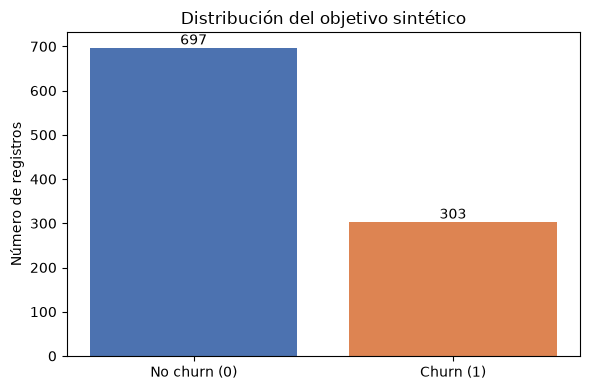

In [22]:
conteo = df[TARGET_COLUMN].value_counts().reindex([0, 1], fill_value=0)
tasa_churn = float(df[TARGET_COLUMN].mean())
print(f"Tasa de churn sintética: {tasa_churn:.1%}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["No churn (0)", "Churn (1)"], conteo.values, color=["#4C72B0", "#DD8452"])
ax.set(title="Distribución del objetivo sintético", ylabel="Número de registros")
for indice, valor in enumerate(conteo.values):
    ax.text(indice, valor, f"{valor:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 4. Distribuciones de las variables

Las variables continuas son `tenure_months`, `satisfaction` y `monthly_hours`. `overtime` es binaria y `promotions` es un conteo discreto; sus distribuciones se resumen por separado.

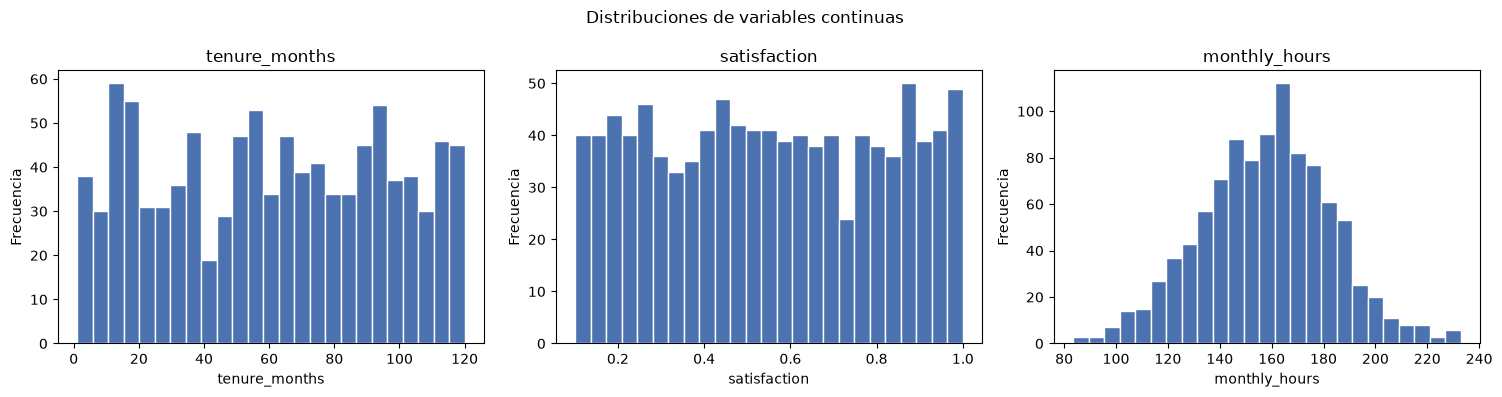

,registros
overtime,
0,708
1,292


,registros
promotions,
0,511
1,355
2,105
3,25
4,4


In [23]:
continuous_columns = ["tenure_months", "satisfaction", "monthly_hours"]
fig, axes = plt.subplots(1, len(continuous_columns), figsize=(15, 4))
for ax, column in zip(axes, continuous_columns):
    ax.hist(df[column], bins=25, color="#4C72B0", edgecolor="white")
    ax.set(title=column, xlabel=column, ylabel="Frecuencia")
fig.suptitle("Distribuciones de variables continuas")
plt.tight_layout()
plt.show()

for column in ["overtime", "promotions"]:
    display(df[column].value_counts().sort_index().rename("registros").to_frame())

## 5. Variables y tasa de churn por grupo

Compara las tasas junto con el número de observaciones: un porcentaje alto en un grupo pequeño puede ser inestable. Estas son asociaciones dentro de la muestra sintética, no efectos causales.

In [24]:
df_analisis = df.assign(
    satisfaction_group=pd.cut(df["satisfaction"], bins=[0, 0.25, 0.5, 0.75, 1.0], include_lowest=True),
    tenure_group=pd.cut(
        df["tenure_months"], bins=[0, 24, 60, 96, 120],
        labels=["1-24", "25-60", "61-96", "97-120"], include_lowest=True,
    ),
)

def resumen_churn_por(columna):
    return (
        df_analisis.groupby(columna, observed=False)[TARGET_COLUMN]
        .agg(registros="size", tasa_churn="mean")
        .assign(tasa_churn=lambda tabla: tabla["tasa_churn"].map(lambda valor: f"{valor:.1%}"))
    )

for columna in ["overtime", "promotions", "satisfaction_group", "tenure_group"]:
    print(f"Tasa por {columna}")
    display(resumen_churn_por(columna))

Tasa por overtime


,registros,tasa_churn
overtime,,
0,708,25.6%
1,292,41.8%


Tasa por promotions


,registros,tasa_churn
promotions,,
0,511,32.9%
1,355,31.5%
2,105,18.1%
3,25,16.0%
4,4,0.0%


Tasa por satisfaction_group


,registros,tasa_churn
satisfaction_group,,
"(-0.001, 0.25]",175,56.0%
"(0.25, 0.5]",272,41.9%
"(0.5, 0.75]",263,22.8%
"(0.75, 1.0]",290,10.7%


Tasa por tenure_group


,registros,tasa_churn
tenure_group,,
1-24,213,41.8%
25-60,278,31.7%
61-96,313,27.8%
97-120,196,19.9%


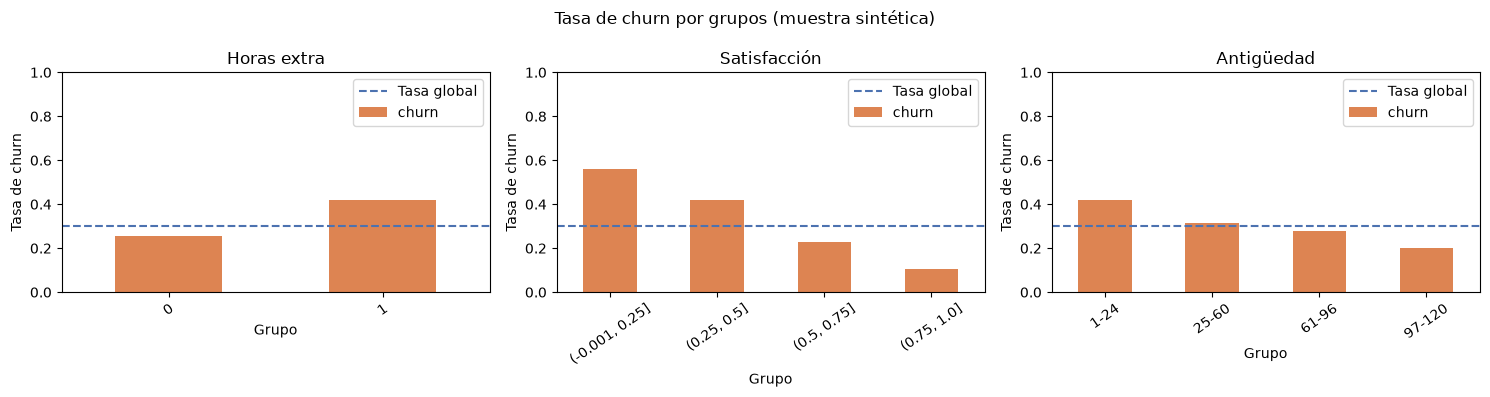

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (column, titulo) in zip(
    axes,
    [("overtime", "Horas extra"), ("satisfaction_group", "Satisfacción"), ("tenure_group", "Antigüedad")],
):
    tasas = df_analisis.groupby(column, observed=False)[TARGET_COLUMN].mean()
    tasas.plot(kind="bar", ax=ax, color="#DD8452")
    ax.axhline(tasa_churn, color="#4C72B0", linestyle="--", label="Tasa global")
    ax.set(title=titulo, xlabel="Grupo", ylabel="Tasa de churn", ylim=(0, 1))
    ax.tick_params(axis="x", rotation=35)
    ax.legend()
fig.suptitle("Tasa de churn por grupos (muestra sintética)")
plt.tight_layout()
plt.show()

## 6. Correlaciones y lectura del generador

La correlación es una medida lineal; no resume todas las relaciones posibles y no implica causalidad. En este caso sí conocemos el mecanismo de simulación: el generador construye la probabilidad de churn con satisfacción, antigüedad, horas, horas extra y promociones, y luego toma una muestra Bernoulli. Usa esta matriz como diagnóstico del ejemplo, no como evidencia del mundo real.

,tenure_months,satisfaction,monthly_hours,overtime,promotions,churn
tenure_months,1.00,-0.01,-0.02,0.01,0.03,-0.16
satisfaction,-0.01,1.00,0.01,-0.02,0.01,-0.36
monthly_hours,-0.02,0.01,1.00,0.00,-0.02,0.07
overtime,0.01,-0.02,0.00,1.00,-0.03,0.16
promotions,0.03,0.01,-0.02,-0.03,1.00,-0.10
churn,-0.16,-0.36,0.07,0.16,-0.10,1.00


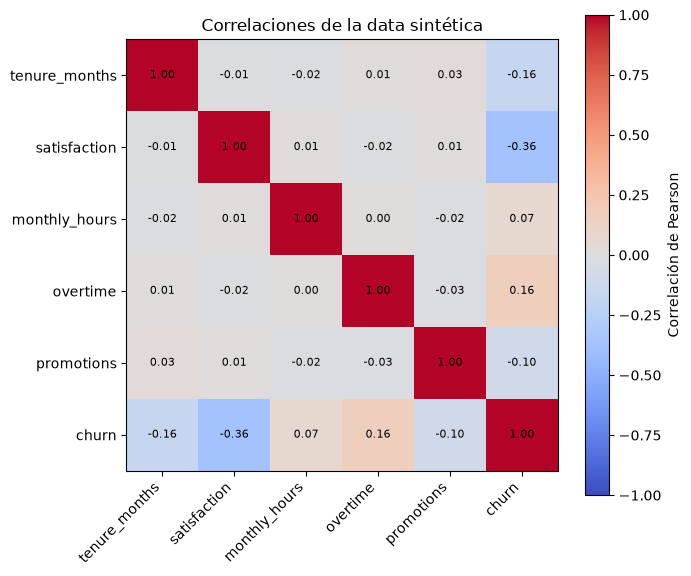

In [27]:
correlaciones = df.corr(numeric_only=True)
display(correlaciones.round(2))

fig, ax = plt.subplots(figsize=(7, 6))
imagen = ax.imshow(correlaciones, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlaciones.columns)), labels=correlaciones.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlaciones.index)), labels=correlaciones.index)
for i in range(len(correlaciones.index)):
    for j in range(len(correlaciones.columns)):
        ax.text(j, i, f"{correlaciones.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")
ax.set_title("Correlaciones de la data sintética")
plt.tight_layout()
plt.show()

## 7. Conclusiones del ejercicio

- La muestra se genera de manera reproducible desde el código del proyecto y no depende de un archivo CSV externo.
- Revisa las tablas y gráficos anteriores para describir balance, rangos y patrones observados en esta ejecución.
- Como la etiqueta y sus probabilidades se simulan a partir de las variables de entrada, las asociaciones son esperables por diseño y **no deben interpretarse como hallazgos sobre empleados reales**.
- Para analizar datos reales sería necesario definir una fuente autorizada, ventana temporal, calidad de etiquetas, posibles sesgos y controles de privacidad.